# **Informe**

---



#Introducción

La detección temprana y precisa del cáncer de mama es uno de los desafíos más críticos en la medicina oncológica actual, dado su impacto directo en las tasas de supervivencia y la efectividad del tratamiento. En este contexto, las técnicas de aprendizaje automático (Machine Learning) han emergido como herramientas poderosas para apoyar el diagnóstico clínico, permitiendo identificar patrones sutiles que pueden diferenciar la naturaleza de un tumor con alta fiabilidad.

El objetivo principal de este proyecto es desarrollar un modelo predictivo capaz de clasificar tumores de mama en dos categorías diagnósticas: malignos o benignos. Para lograrlo, se trabajó con un conjunto de datos clínicos compuesto por 30 características cuantitativas derivadas de resultados de biopsias

Antes de la fase de modelado, se llevó a cabo un Análisis Exploratorio de Datos (EDA) exhaustivo. Esta etapa preliminar fue fundamental para comprender la distribución de las variables, identificar correlaciones significativas entre las características morfológicas y detectar posibles anomalías o sesgos en la información. El presente informe detalla el proceso completo, desde el análisis estadístico de dichas características hasta la implementación y evaluación del rendimiento del algoritmo de clasificación seleccionado.

#EDA

La fase inicial del análisis comenzó con una inspección preliminar de la estructura y el contenido del conjunto de datos. Se evaluó la dimensionalidad original, la cual constaba de 569 observaciones y 33 variables, y se visualizaron las primeras instancias para comprender la organización de la información. A continuación, se calcularon estadísticos descriptivos clave y se realizó una verificación de la integridad de los datos, confirmando la ausencia absoluta de valores nulos.

Durante este proceso de auditoría de datos, se identificó la columna 'Unnamed 32' como un atributo irrelevante y carente de información significativa, por lo que se procedió a su eliminación. Tras esta etapa de depuración, la dimensionalidad del dataset se ajustó a una forma final de (569, 32). Por último, se validaron los tipos de datos correspondientes a cada variable para asegurar su consistencia con las operaciones analíticas subsiguientes.

Posteriormente, se analizó la distribución de la variable objetivo diagnosis, de naturaleza categórica dicotómica (etiquetas: 'M' para maligno, 'B' para benigno). El conteo de frecuencias reveló 357 instancias benignas y 212 malignas, lo que corresponde a proporciones del 62,7% y 37,3%, respectivamente. Esta diferencia porcentual confirma la existencia de un desbalance de clases en el conjunto de datos, factor que deberá ser considerado en la estrategia de validación del modelo

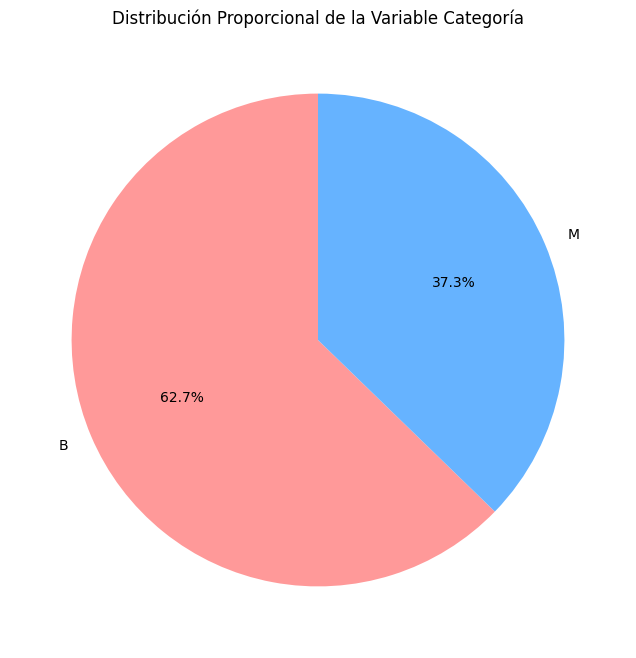

Se llevó a cabo un análisis univariante de las 30 características mediante la visualización de sus histogramas para determinar la forma de sus distribuciones, complementado con diagramas de caja (boxplots) para la identificación de valores atípicos (outliers).

Aunque los gráficos evidenciaron la presencia de múltiples valores fuera de los rangos intercuartílicos habituales, se decidió no eliminar ni transformar dichas observaciones. Esta decisión se fundamenta en la naturaleza biológica de los datos: en el contexto oncológico, los valores extremos suelen reflejar variabilidad fenotípica real o estados patológicos avanzados, y no errores de medición. Preservar esta información es crucial para que el modelo generalice correctamente sobre casos clínicos severos


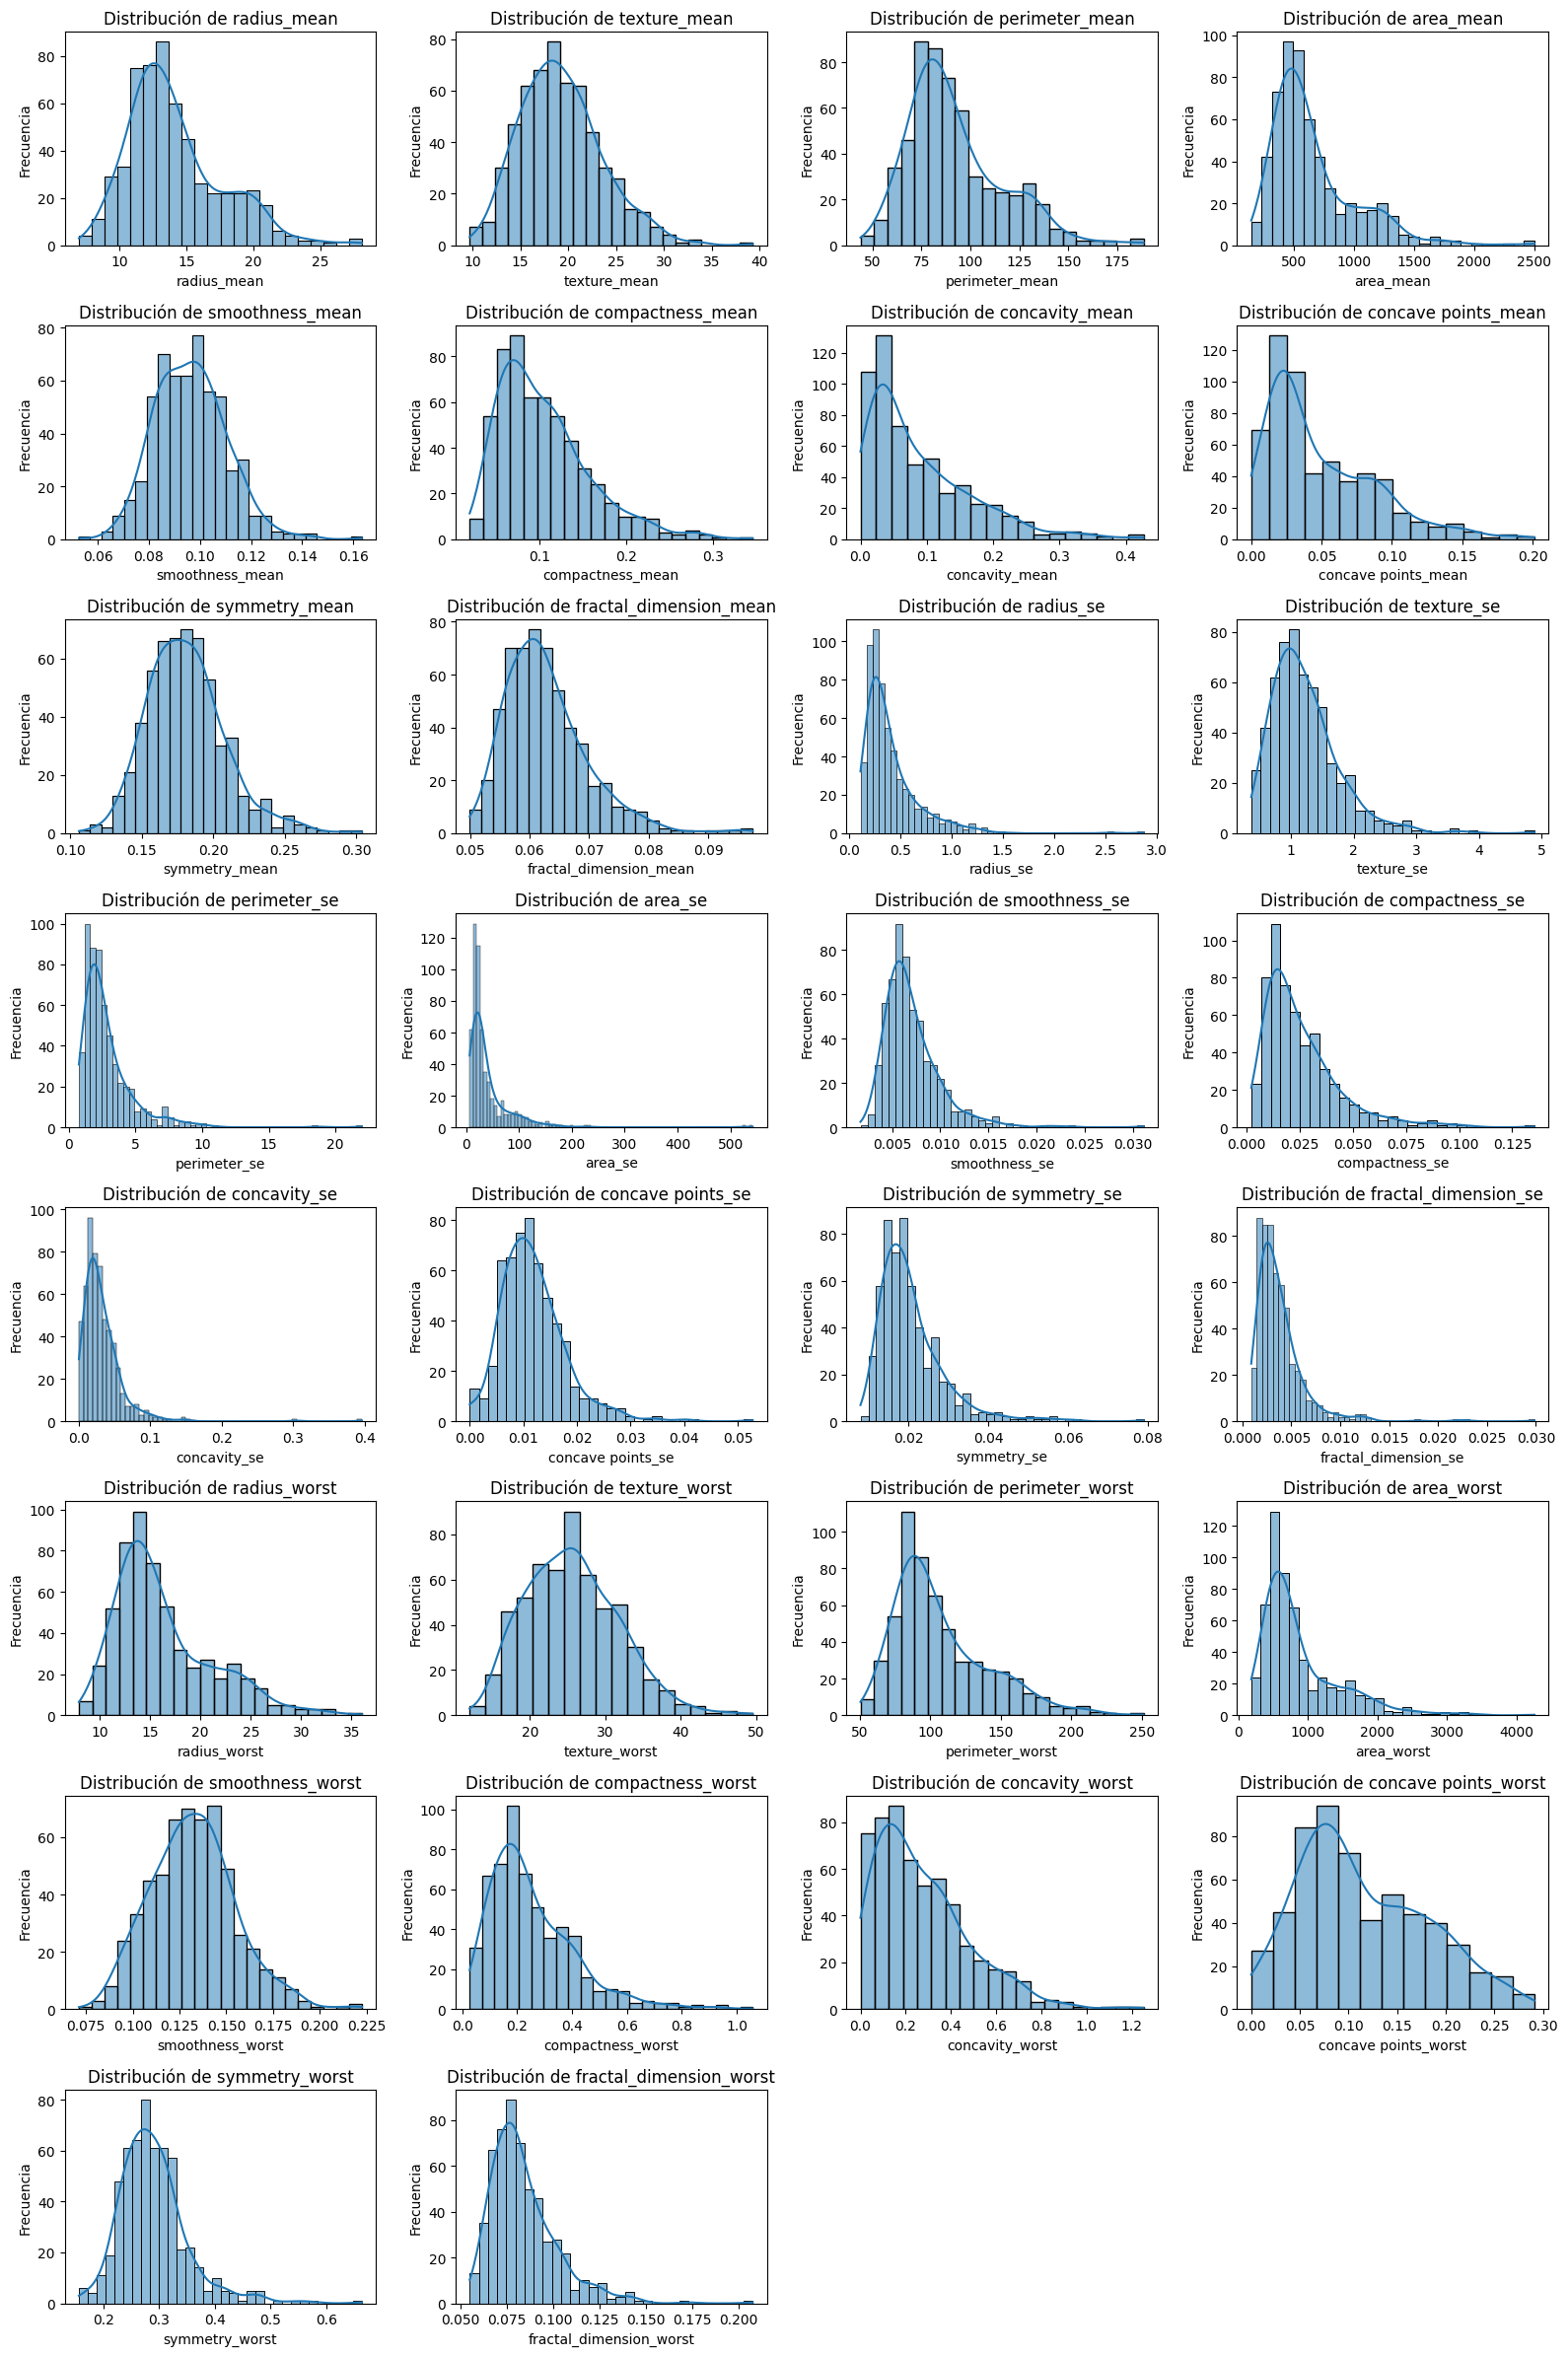

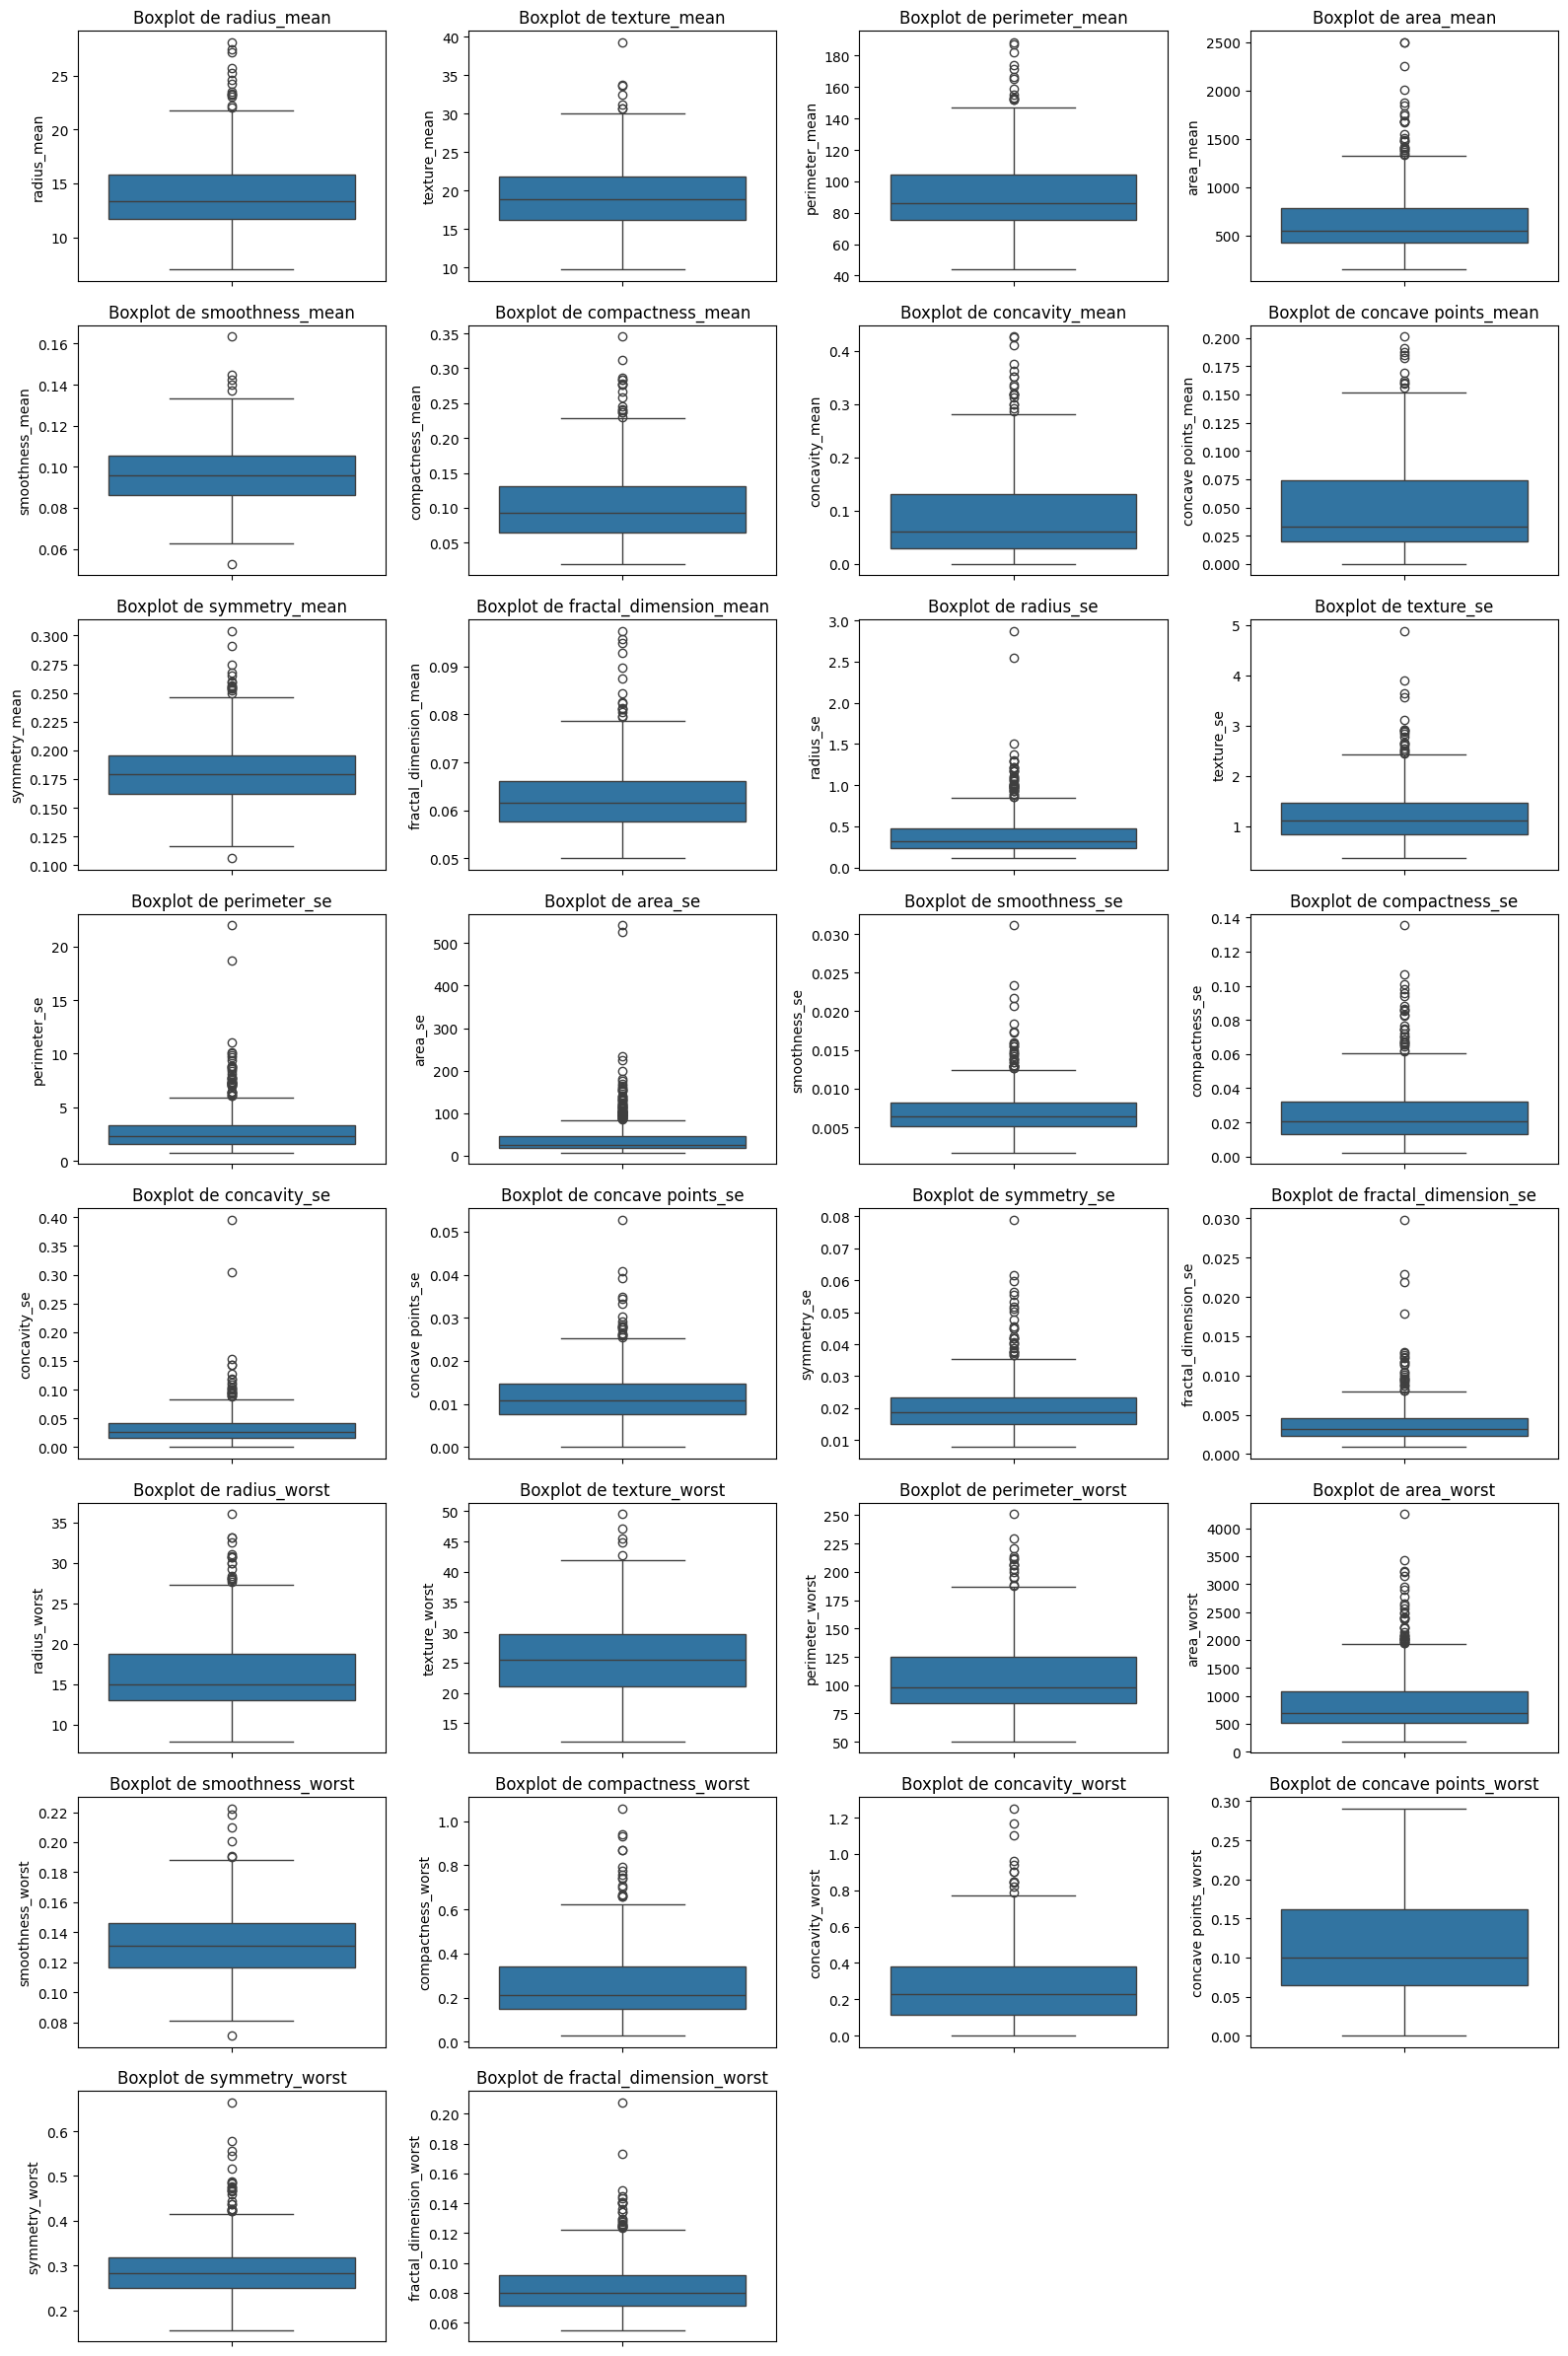

Posteriormente, se calcularon las medidas de tendencia central y dispersión. Durante este análisis, se detectó un comportamiento particular en la moda de un subconjunto específico de variables morfológicas: concavity_mean, concave points_mean, concavity_se, concave points_se, concavity_worst y concave points_worst.

En estas características, la moda se sitúa en 0, un hallazgo que posee una interpretación física y clínica relevante. Un valor nulo en estas métricas indica la ausencia de concavidades en el contorno del núcleo celular (es decir, una morfología suave y convexa). Este rasgo es consistente con la estructura celular de tejidos sanos o tumores benignos, lo que sugiere que estos valores cero son indicadores informativos ('signales') y no datos faltantes

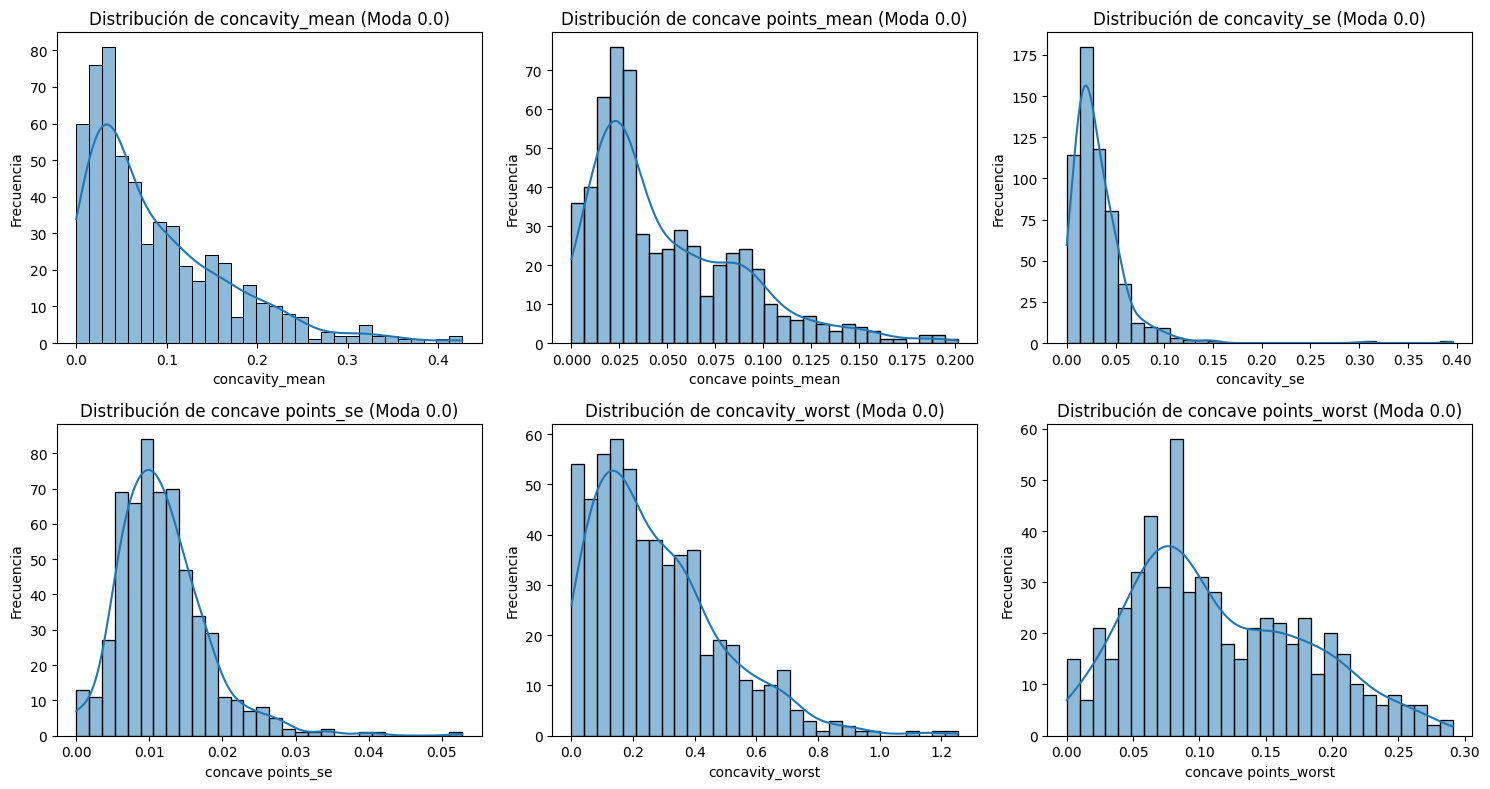

Para evaluar el poder discriminante de cada variable individualmente, se generaron diagramas de caja (boxplots) estratificados por la variable objetivo (diagnosis). Este análisis permitió contrastar las distribuciones de las características morfológicas entre los grupos de tumores benignos y malignos.

Si bien se observó una tendencia general donde los casos malignos presentan valores significativamente más altos en características de tamaño y geometría (como radius, perimeter, concavity), la visualización reveló un fenómeno crítico para el modelado: la existencia de superposición en los rangos de distribución (overlap).

Específicamente, se detectaron observaciones atípicas (outliers) con implicaciones clínicas importantes:

Falsos positivos potenciales: Casos benignos que exhiben valores extremos altos, situándose dentro del rango intercuartílico típico de la clase maligna.

Falsos negativos potenciales: Casos malignos con valores inusualmente bajos, que se confunden con la distribución de la clase benigna.

Esta intersección entre las distribuciones confirma que las clases no son linealmente separables utilizando una única característica (univariante). La presencia de estos casos 'limítrofes' justifica matemáticamente la necesidad de utilizar algoritmos de aprendizaje automático multivariantes, capaces de trazar fronteras de decisión complejas (hiperplanos o superficies no lineales) en un espacio n-dimensional para minimizar el error de clasificación

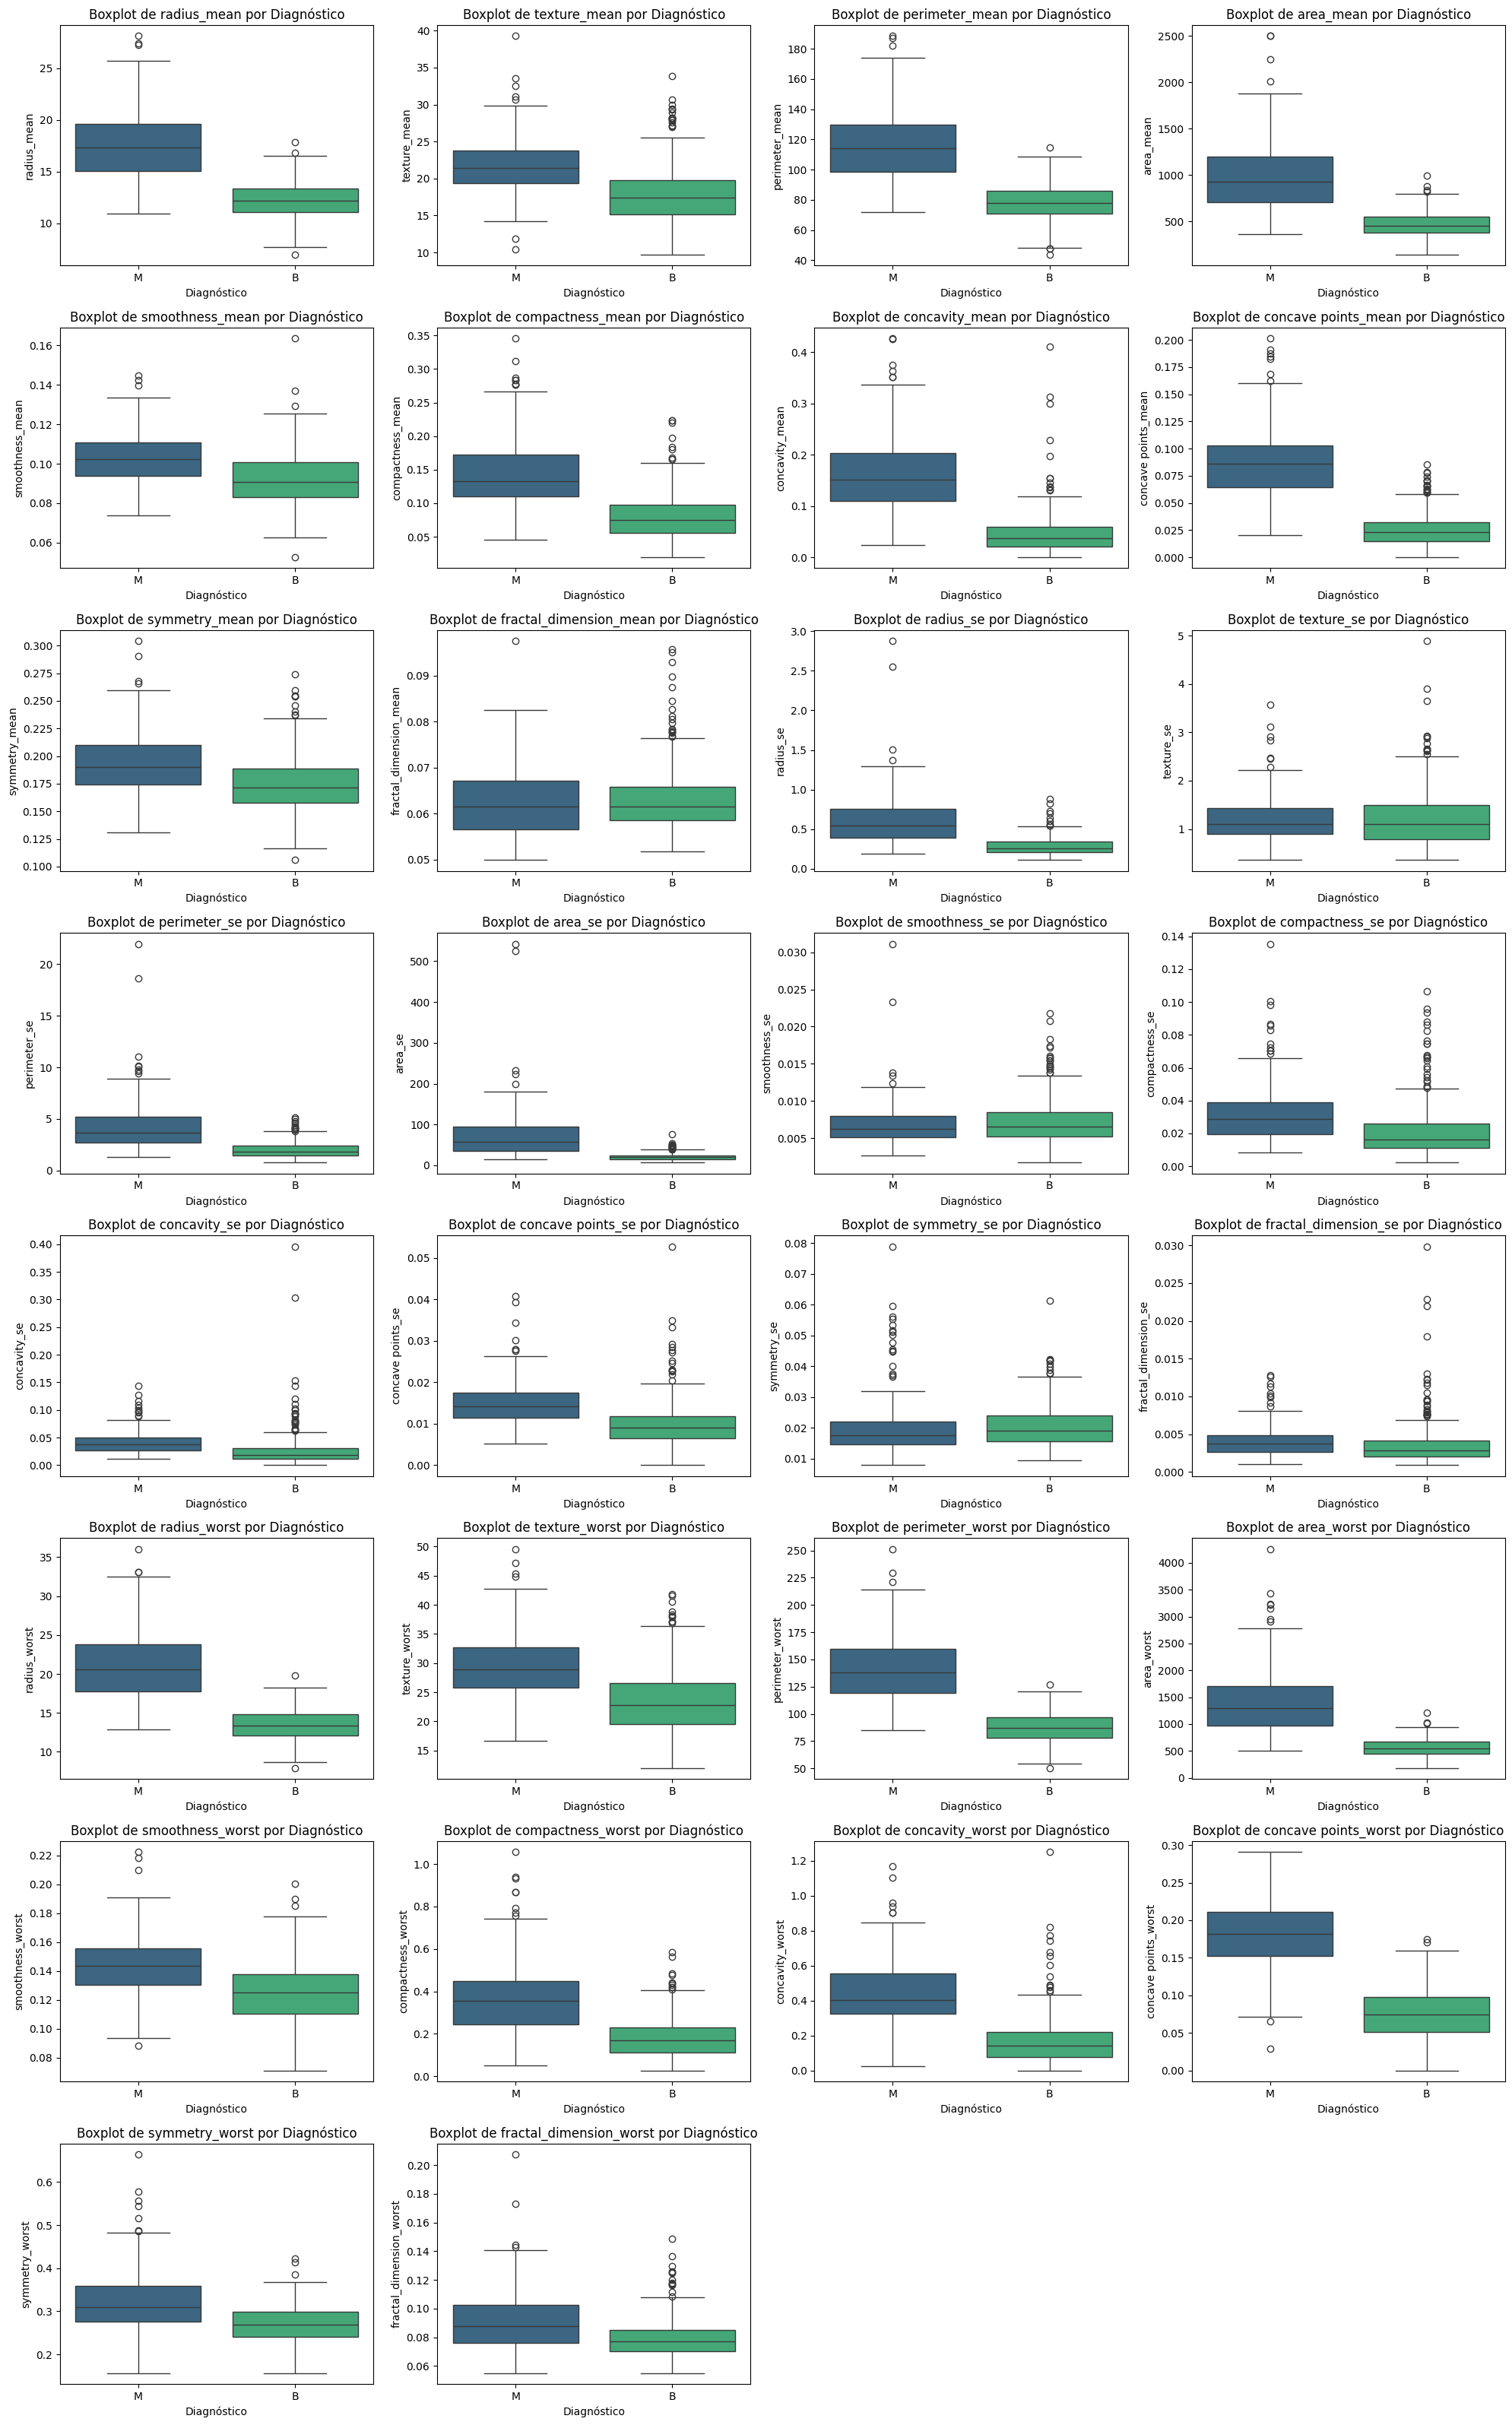

Para cuantificar las relaciones lineales entre las variables numéricas y la variable objetivo, se calculó la matriz de correlación de Pearson. Previo a este cálculo, la variable diagnosis fue codificada numéricamente (M=1,B=0), permitiendo interpretar el signo y la magnitud de los coeficientes en términos de riesgo de malignidad.

1. Correlación con el Diagnóstico (Poder Discriminante): El análisis del vector de correlación respecto a la variable objetivo reveló patrones consistentes con los hallazgos visuales previos (boxplots). Se observaron coeficientes positivos altos (cercanos a +1) en características geométricas clave como radius, perimeter, area y concave points (en sus versiones mean, se y worst). Matemáticamente, esto indica una relación directamente proporcional: a mayor magnitud de estas características, mayor es la probabilidad de que la instancia corresponda a la clase positiva (Maligno). Esto confirma que dichas variables poseen un alto poder discriminante y son candidatas prioritarias para el modelo predictivo.

2. Correlación entre Características (Multicolinealidad): La estructura interna de la matriz evidenció una fuerte multicolinealidad entre varios predictores, identificada por coeficientes ∣r∣>0.9. Este fenómeno se atribuye a dos factores principales:

Dependencia Geométrica: Variables como radius, perimeter y area están funcionalmente relacionadas, lo que genera una redundancia de información casi perfecta.

Dependencia de Medición: Existe una alta correlación entre las diferentes estadísticas derivadas de una misma medición base (p. ej., fuerte relación entre radius_mean, radius_se y radius_worst).

Implicaciones para el Modelado: La presencia de multicolinealidad severa plantea desafíos para ciertos algoritmos (como la regresión logística), ya que puede inflar la varianza de los coeficientes estimados y dificultar su interpretación. Este hallazgo sugiere la necesidad de aplicar técnicas de selección de características (para eliminar variables redundantes) o métodos de reducción de dimensionalidad (como PCA) para proyectar la información en un espacio ortogonal antes del entrenamiento."

Como resultado directo de este análisis matricial, se procedió a aislar y jerarquizar las variables con mayor correlación absoluta respecto al diagnóstico, estableciendo así el subconjunto de características más influyentes para la etapa de aprendizaje

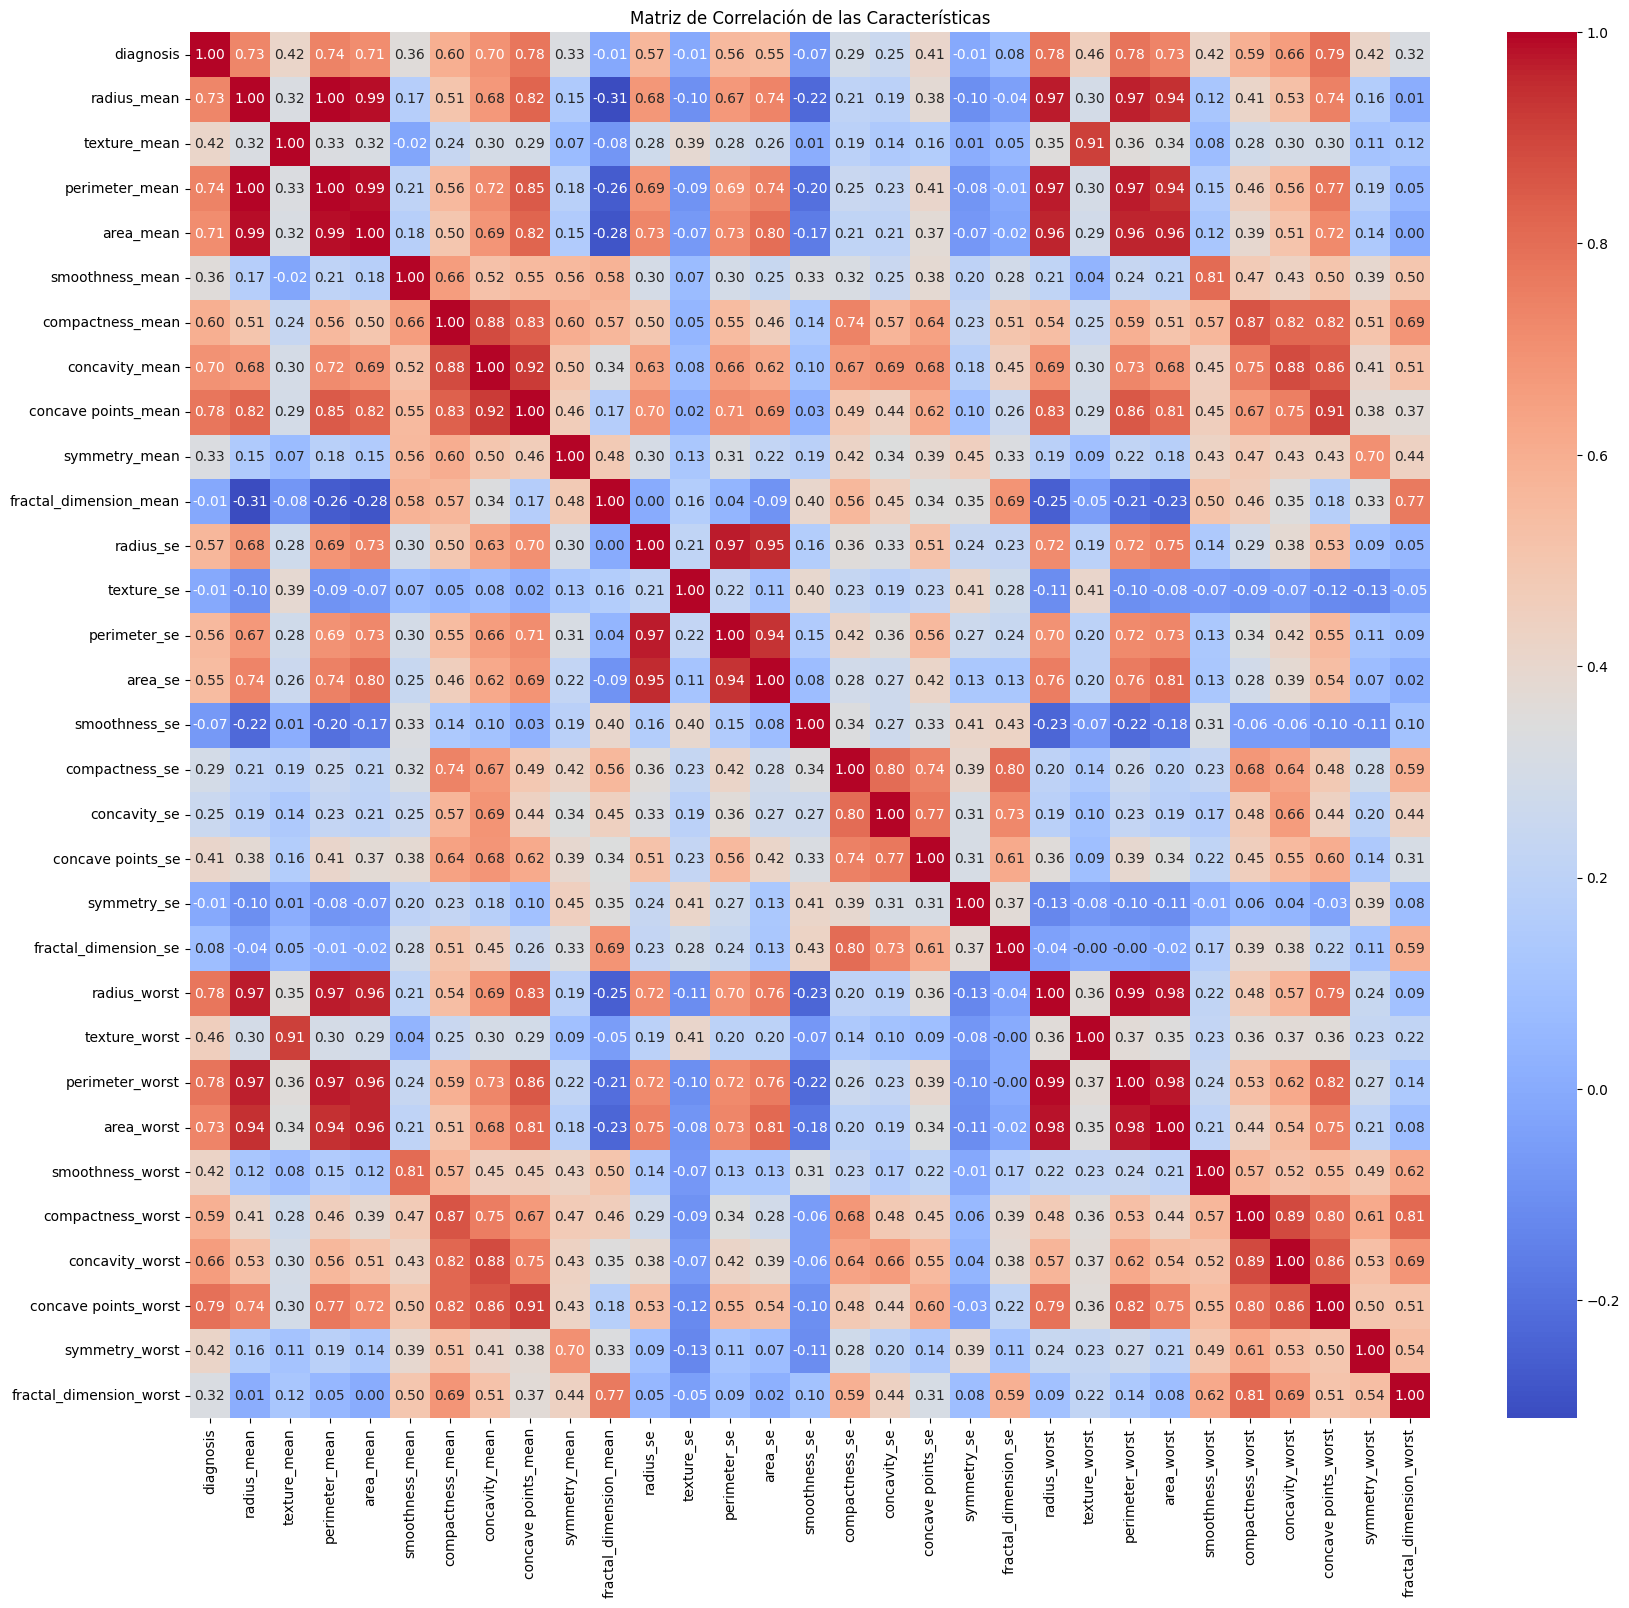

El subconjunto de características con mayor carga predictiva es el siguiente:

concave points_worst: 0.79

perimeter_worst: 0.78

concave points_mean: 0.78

radius_worst: 0.78

perimeter_mean: 0.74

area_worst: 0.73

radius_mean: 0.73

area_mean: 0.71

Los resultados cuantitativos obtenidos corroboran las observaciones cualitativas derivadas previamente de los diagramas de caja (boxplots), confirmando dos patrones fundamentales para la discriminación entre clases:

Geometría y Tamaño: Las métricas dimensionales (radius, perimeter, area) mantienen una correlación positiva fuerte y consistente. Esto valida la premisa biológica de que los tumores malignos tienden a presentar un crecimiento descontrolado y, por ende, dimensiones mayores.

Morfología e Irregularidad: La alta correlación de concave points (puntos cóncavos en el contorno) destaca la importancia de la textura y la forma del núcleo. Los contornos irregulares o dentados son indicadores críticos de malignidad.

Predominancia de Valores Extremos ('Worst'): Es estadísticamente relevante que las variantes con el sufijo _worst (que representan el promedio de los valores más extremos observados en la muestra) ocupen las primeras posiciones en la jerarquía de correlación. Esto sugiere que los valores límite o extremos poseen mayor capacidad de separación de clases (poder discriminante) que los valores promedio globales.

Basado en este análisis, este conjunto de variables constituye la señal predictiva más fuerte del dataset

Se realizó un análisis visual de las relaciones por pares seleccionando las variables con mayor coeficiente de correlación. Se generaron diagramas de dispersión (scatter plots) para proyecciones bidimensionales específicas, tales como radius_mean vs perimeter_mean y perimeter_worst vs concave points_worst. Observaciones sobre la Distribución Espacial:

Formación de Clústeres: La visualización revela una segregación espacial evidente entre las clases. Las instancias benignas ('B') tienden a agruparse compactamente en la región de valores bajos (cuadrante inferior izquierdo), mientras que las malignas ('M') se dispersan hacia valores de mayor magnitud.

Separabilidad Cuasi-Lineal: En la mayoría de las proyecciones analizadas, se observa que una frontera de decisión simple (incluso lineal) podría separar la gran mayoría de las instancias con un alto grado de precisión. Esto confirma que las variables morfológicas seleccionadas poseen una alta señal predictiva.

Implicaciones para la Complejidad del Modelo:A pesar de la clara distinción general, los gráficos evidencian una región de intersección (solapamiento) entre ambas distribuciones. En esta zona limítrofe coexisten tumores benignos con características atípicas (altas) y tumores malignos con características sutiles (bajas).Desde una perspectiva de modelado, la existencia de esta 'zona difusa' implica que: Un modelo lineal simple podría tener un error irreducible en esta frontera

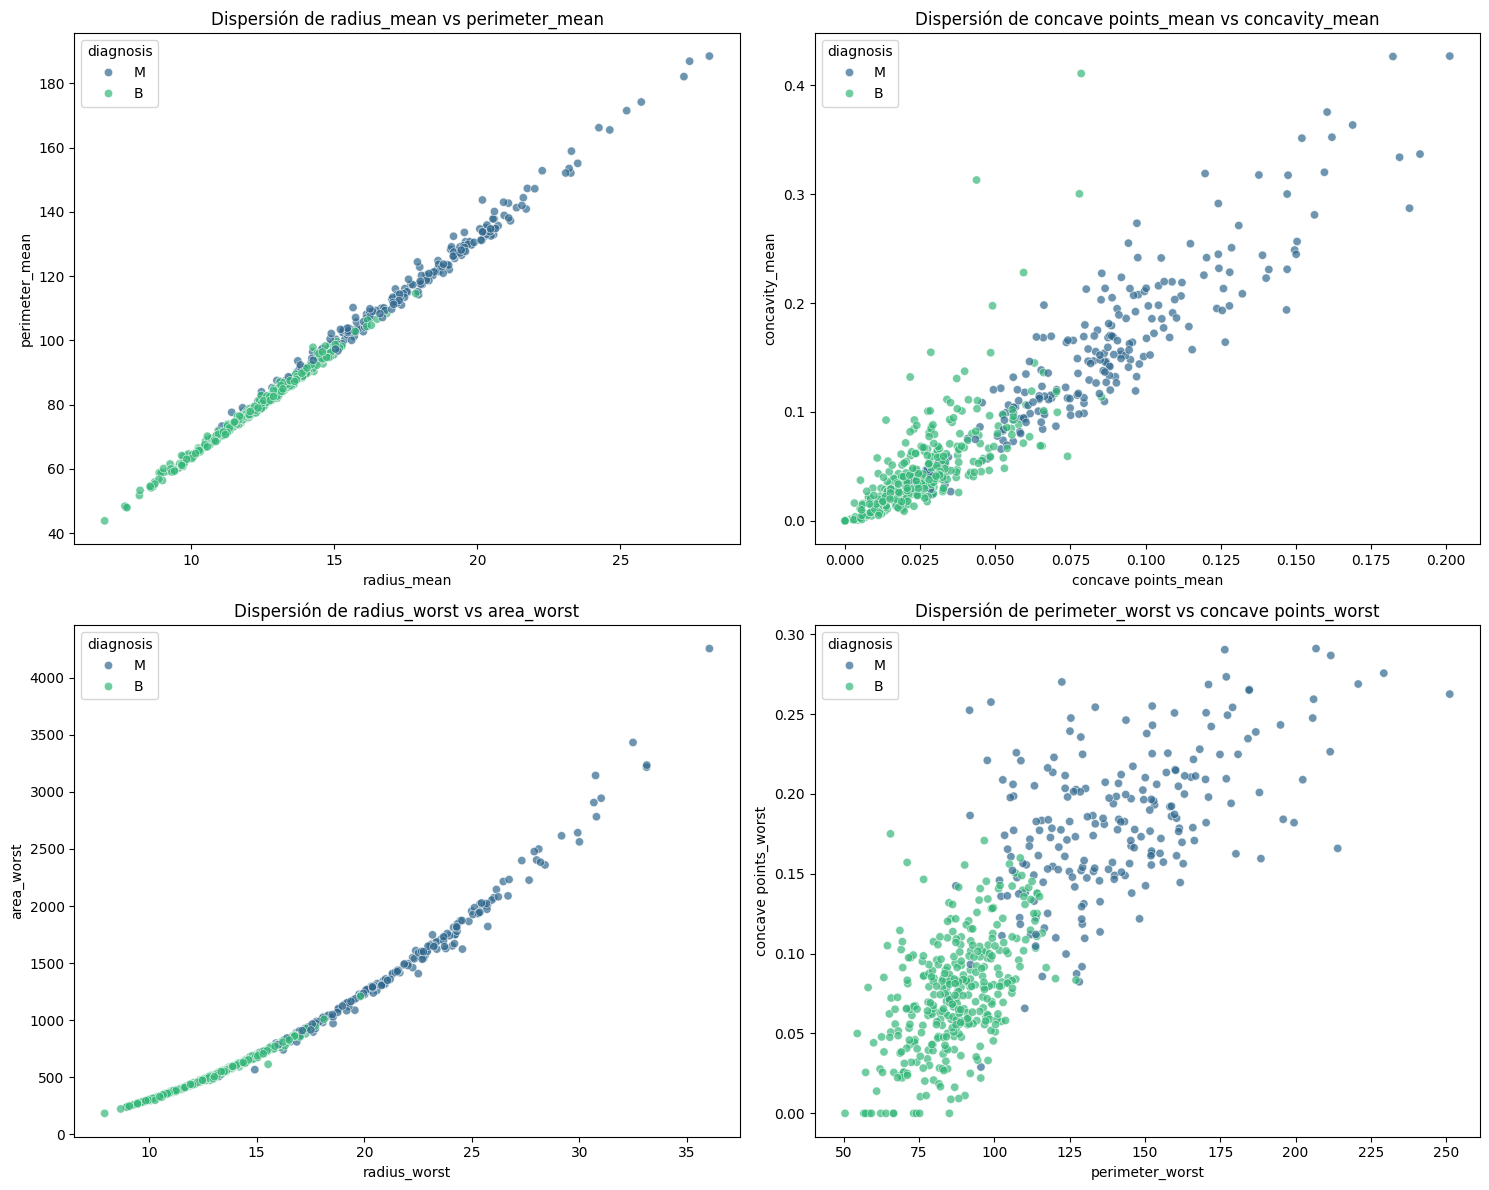

Reducción de Dimensionalidad: Análisis de Componentes Principales (PCA)
Con el objetivo de mitigar la multicolinealidad detectada en la matriz de correlación y proyectar la información en un espacio de menor dimensión que maximice la varianza, se aplicó el Análisis de Componentes Principales (PCA).

1. Preprocesamiento y Estandarización Previo a la descomposición espectral, se procedió a separar la matriz de características X (569×30) del vector objetivo y. Dado que el PCA es sensible a la escala de las variables (al buscar direcciones de máxima varianza), se aplicó una estandarización a todas las características numéricas, transformándolas para que posean una media μ=0 y una desviación estándar σ=1.

2. Varianza Explicada y Selección de Componentes El análisis de los valores propios (eigenvalues) resultantes arrojó la siguiente distribución de información:

PC1 (Primer Componente Principal): Captura el 44.27% de la varianza total del sistema.

PC2 (Segundo Componente Principal): Captura el 18.97%.

La varianza acumulada indica que las dos primeras componentes ortogonales retienen el 63.24% de la información original. Al considerar las primeras 5 componentes, la varianza explicada asciende al 84.73%. El gráfico de varianza acumulada (método del codo) sugiere que la mayor ganancia de información se concentra en las primeras dimensiones, validando la eficacia de la técnica para comprimir la señal del dataset.

3. Proyección en el Subespacio Latente (2D) La visualización del dataset proyectado en el plano definido por PC1 y PC2 reveló una forma favorable para la clasificación. Se observa una separación nítida entre las clases: las instancias benignas y malignas ocupan regiones distintas del plano, con una zona de intersección acotada. Esto confirma que la estructura fundamental de los datos es separable incluso tras una reducción drástica de dimensionalidad.


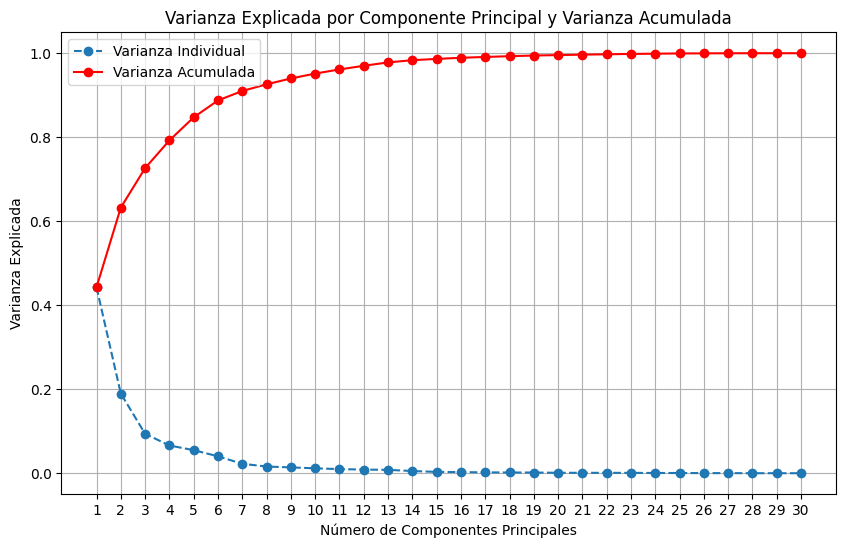

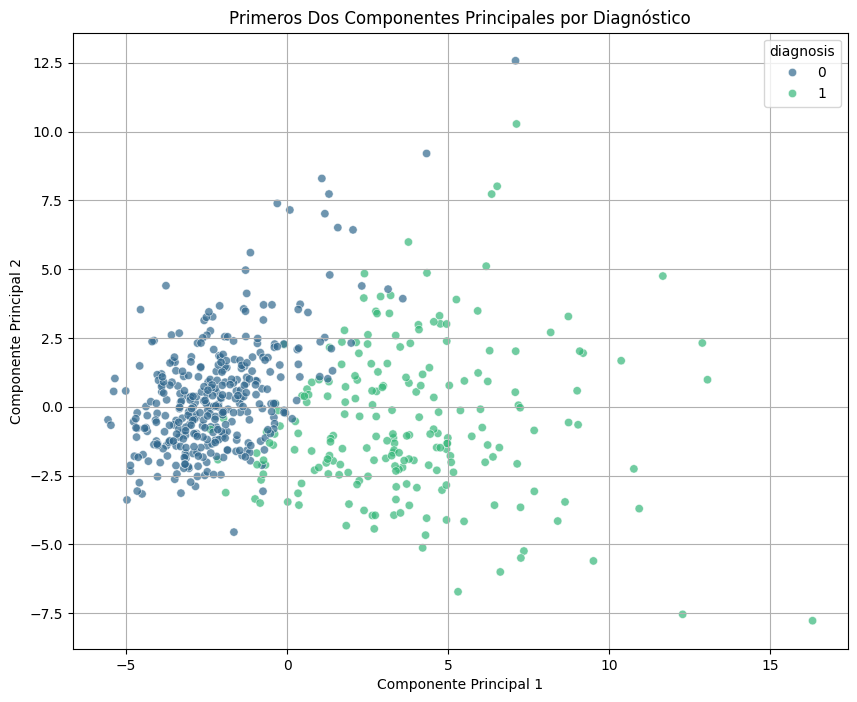

#Construcción de modelos de clasificación

##Modelo 1: Regresión Logística

El modelo de Regresión Logística obtuvo un Accuracy del 97.66%. Esto indica que el modelo predice correctamente el tipo de diagnóstico en casi el 98% de los casos en el conjunto de prueba.

Desglose del Rendimiento:
Precisión (Precision):

Para la clase '0' (Benigno): 0.98. De todos los casos que el modelo predijo como beningnos, el 98% fueron realmente beningnos.

Para la clase '1' (Maligno): 0.97. De todos los casos que el modelo predijo como malignos, el 97% fueron realmente malignos.

Recall (Sensibilidad):

Para la clase '0' (Benigno): 0.98. El modelo identificó correctamente el 98% de todos los casos beningnos reales.

Para la clase '1' (Maligno): 0.97. El modelo identificó correctamente el 97% de todos los casos malignos reales.

F1-Score:

Para ambas clases, el F1-score es de 0.97 y 0.98 respectivamente, lo que sugiere un buen equilibrio entre precisión y recall para ambas categorías.

Matriz de Confusión:
$$\begin{bmatrix}
105 & 2  \\
 2 & 62
 \end{bmatrix}$$

Verdaderos Negativos (TN): 105. El modelo predijo correctamente 105 casos beningnos.

Falsos Positivos (FP): 2. El modelo predijo incorrectamente 2 casos como malignos cuando eran beningnos (errores tipo I).

Falsos Negativos (FN): 2. El modelo predijo incorrectamente 2 casos como beningnos cuando eran malignos (errores tipo II).

Verdaderos Positivos (TP): 62. El modelo predijo correctamente 62 casos malignos.

Curva ROC y AUC:
El área bajo la curva ROC (AUC) es de 0.99. Un valor de AUC tan cercano a 1.0 indica que el modelo tiene una excelente capacidad para distinguir entre las clases positiva y negativa. El modelo tiene una alta probabilidad de clasificar correctamente un ejemplo positivo elegido al azar y un ejemplo negativo elegido al azar.

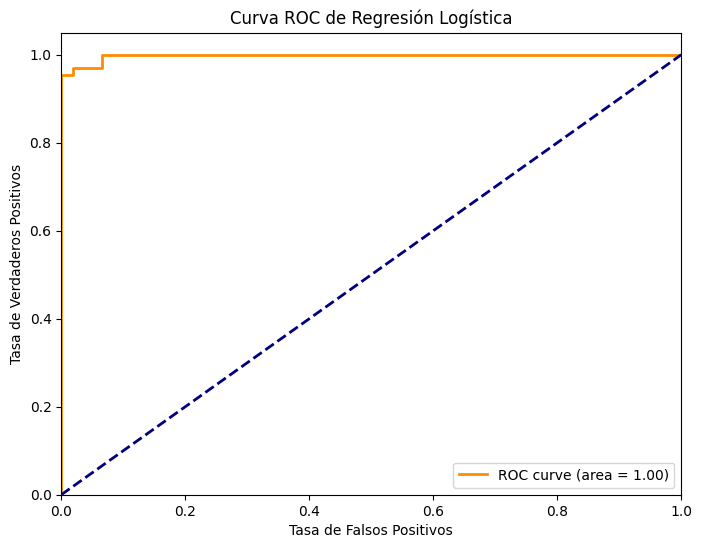

##Modelo 2: SVM

###Kernel Polinomial

Métricas de Evaluación del Modelo SVM con Kernel Polinomial
Accuracy (Exactitud): 0.91

El modelo SVM con kernel polinomial clasificó correctamente al 91% de las muestras en el conjunto de prueba. Este valor es notablemente inferior al de la Regresión Logística (97.7%).

Classification Report (Reporte de Clasificación):

Precision:
Para la clase 0 (Benigno): 0.88

Para la clase 1 (Maligno): 1.00 Este modelo obtuvo una precisión perfecta para la clase maligna, lo que significa que cada vez que predijo un caso como 'Maligno', acertó.

Recall (Sensibilidad):
Para la clase 0 (Benigno): 1.00. Identificó correctamente todos los casos benignos.

Para la clase 1 (Maligno): 0.77 De los casos malignos reales, solo identificó correctamente el 77%. Este es un recall mucho más bajo que los otros modelos.

F1-Score: 0.93 para Benigno y 0.87 para Maligno. El F1-score para maligno es significativamente más bajo.

Confusion Matrix (Matriz de Confusión):

$$\begin{bmatrix}
107 & 0 \\
15 & 49
\end{bmatrix}$$

Verdaderos Negativos (TN): 107
Todos los casos benignos fueron predichos correctamente.

Falsos Positivos (FP): 0
No hubo falsos positivos, lo cual es excelente.

Falsos Negativos (FN): 15
Se predijeron 15 casos como 'Benignos' cuando en realidad eran 'Malignos'

Verdaderos Positivos (TP): 49

Curva ROC y AUC del Modelo SVM con Kernel Polinomial
AUC (Area Under the Curve): 0.99

A pesar del bajo recall y la accuracy, el AUC sigue siendo muy alto. Esto es un buen ejemplo de cómo el AUC puede ser engañoso en casos de desbalance de clases o cuando el rendimiento de recall es pobre. Un AUC alto solo indica la capacidad general de distinguir entre clases, pero no dice mucho sobre cuántas instancias de la clase minoritaria fueron realmente identificadas.

El SVM con kernel polinomial (degree=3) mostró un rendimiento significativamente inferior en Accuracy y, crucialmente, en Recall para la clase Maligna en comparación con los otros modelos.
El número de Falsos Negativos se disparó a 15, lo cual es inaceptable en un contexto de diagnóstico de cáncer, ya que esto significa que 15 pacientes con cáncer real serían diagnosticados como benignos.
Aunque mantuvo una Precision de 1.00 para la clase Maligna (no tuvo falsos positivos), el bajo Recall lo hace un modelo menos deseable para este problema específico, donde identificar correctamente los casos malignos es vital.




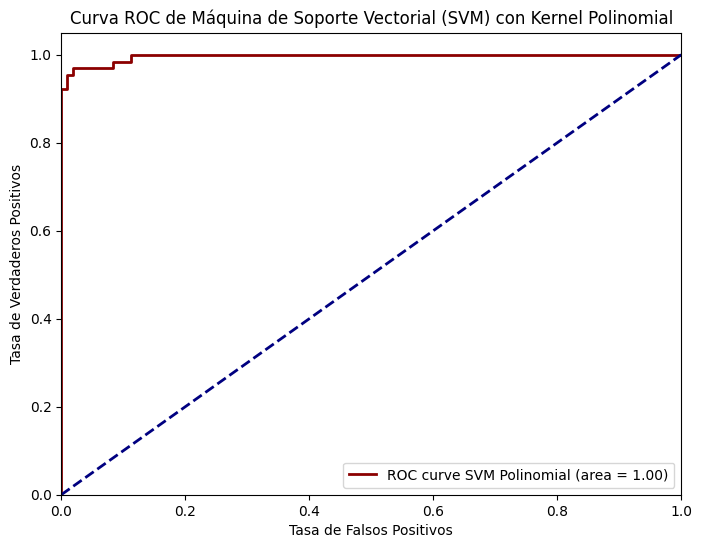

###Kernel Radial

Métricas de Rendimiento Global

El modelo alcanzó una Exactitud (Accuracy) del 97%, un resultado robusto, aunque se sitúa ligeramente por debajo de la Regresión Logística. Asimismo, el Área Bajo la Curva ROC (AUC) se mantuvo en 0.99, demostrando una consistencia excepcional en la capacidad del modelo para clasificar y ordenar probabilísticamente las instancias.

Análisis de la Matriz de Confusión

La descomposición de los aciertos y errores se visualiza en la siguiente matriz:
$$\begin{bmatrix}
105 & 2 \\
3 & 61
\end{bmatrix}$$

Verdaderos Negativos (TN): 105. El modelo identificó correctamente la totalidad de los casos benignos (Especificidad = 0.97).

Falsos Positivos (FP): 2 Esto implica una Precisión (Clase Maligna) de 0.97

Falsos Negativos (FN): 3. Se clasificaron erróneamente 3 tumores malignos como benignos.

El análisis de las métricas de sensibilidad (Recall) arroja un valor de 0.95 para la clase maligna.




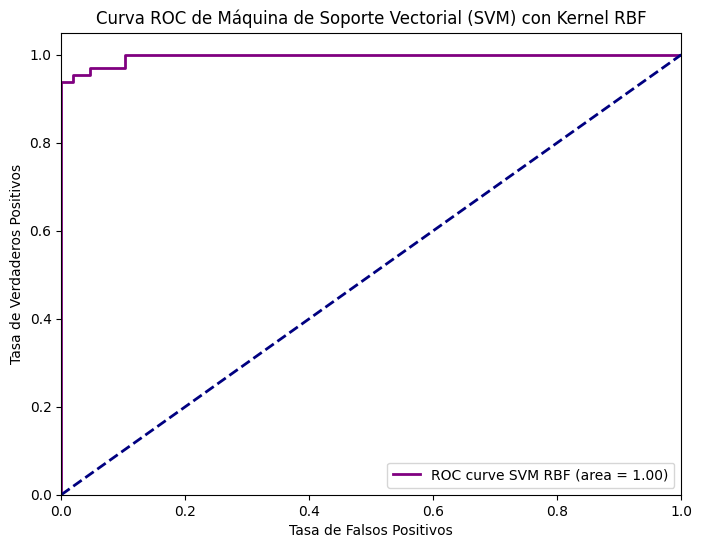

###Kernel Lineal

El modelo alcanzó una Exactitud Global (Accuracy) del 97%.

El análisis detallado por clase revela un comportamiento asimétrico:

Precisión (Clase Maligna): 0.97

Sensibilidad (Recall - Clase Maligna): 0.95. Aquí radica la diferencia crítica. El modelo identificó correctamente el 95% de los casos positivos reales.

Análisis de la Matriz de Confusión

La distribución de errores y aciertos se presenta en la siguiente matriz:

$$\begin{bmatrix}
105 & 2 \\
3 & 61
\end{bmatrix}$$

Verdaderos Negativos (TN): 105.

Falsos Positivos (FP - Error Tipo I): 2

Falsos Negativos (FN - Error Tipo II): 3. Este es el hallazgo más relevante desde la perspectiva clínica. El modelo falló en detectar 3 casos de cáncer, clasificándolos erróneamente como benignos.

Discriminación Global (AUC-ROC)

El Área Bajo la Curva (AUC) se sitúa en 0.99, un valor virtualmente idéntico al de la Regresión Logística.Esto sugiere que, aunque el punto de operación por defecto del SVM resulta en más Falsos Negativos, la capacidad intrínseca del modelo para separar las distribuciones es excelente. La diferencia en el Recall final podría atribuirse a la naturaleza del algoritmo SVM, que prioriza la maximización del margen sobre la probabilidad posterior, haciéndolo menos flexible en los límites de decisión comparado con la función sigmoide logística en este dataset específico.

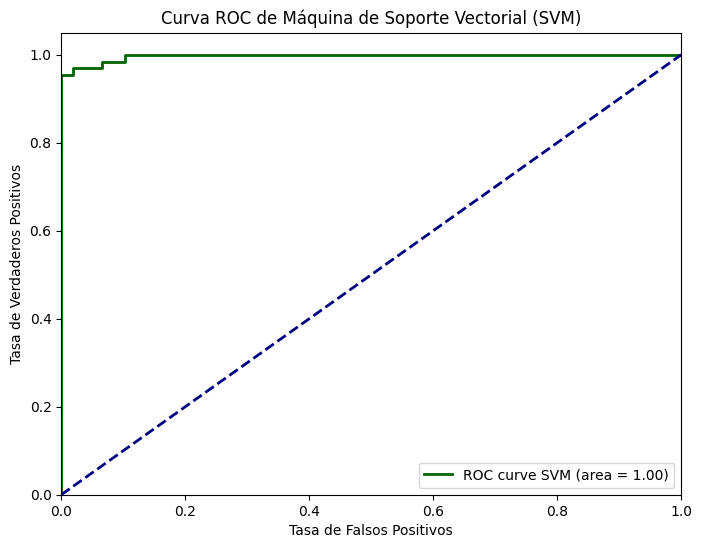

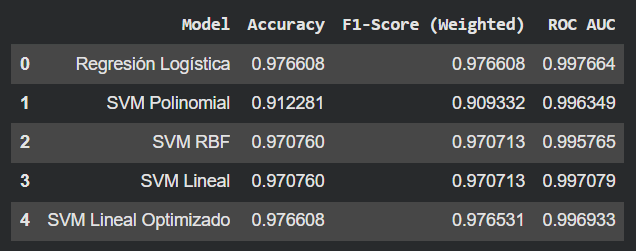

#Preguntas

##¿Por qué es más importante el Recall que la Precisión en el contexto de diagnóstico de cáncer?


Recall (Sensibilidad o Tasa de Verdaderos Positivos): Mide la proporción de casos positivos reales que el modelo identificó correctamente. Es decir, ¿cuántos de los pacientes que realmente tienen cáncer fueron detectados por el modelo?

Recall = Verdaderos Positivos / (Verdaderos Positivos + Falsos Negativos)
Precision (Precisión o Valor Predictivo Positivo): Mide la proporción de predicciones positivas que el modelo hizo que realmente eran correctas. Es decir, de todas las veces que el modelo dijo que un paciente tenía cáncer, ¿cuántas veces acertó?

Precision = Verdaderos Positivos / (Verdaderos Positivos + Falsos Positivos)
¿Por qué Recall es más importante en el diagnóstico de cáncer?
La clave está en los tipos de errores y sus consecuencias:

Falsos Negativos (FN): Un Falso Negativo ocurre cuando el modelo predice que un paciente NO tiene cáncer, pero en realidad SÍ lo tiene.

Consecuencia: Esta es la situación más peligrosa y crítica en el diagnóstico de cáncer. Un Falso Negativo significa que un cáncer real pasa desapercibido, lo que lleva a un retraso en el diagnóstico y tratamiento. El cáncer puede progresar, volverse más avanzado y difícil de tratar, y en última instancia, puede ser fatal. El costo de no detectar un cáncer a tiempo es inmenso, tanto en términos de salud del paciente como en el costo social y económico.

Minimizar Falsos Negativos = Maximizar Recall. Por lo tanto queremos que el Recall sea lo más alto posible para asegurarnos de que se detecten la mayor cantidad posible de casos de cáncer.
Falsos Positivos (FP): Un Falso Positivo ocurre cuando el modelo predice que un paciente SÍ tiene cáncer, pero en realidad NO lo tiene.

Consecuencia: Aunque no es deseable, un Falso Positivo es generalmente menos grave que un Falso Negativo. Lleva a ansiedad innecesaria para el paciente, más pruebas de seguimiento (biopsias, escáneres, etc.) que pueden ser invasivas y costosas, y un uso ineficiente de los recursos sanitarios. Sin embargo, en última instancia, el paciente es diagnosticado como sano.




## ¿Si tuvieras que elegir un modelo para un sistema de apoyo diagnóstico real, ¿cuál elegirías y por qué?


La Regresión Logística presentó el Recall más alto para la clase Maligno (0.97) y, crucialmente, el menor número de Falsos Negativos (solo 2). Esto significa que es el modelo que tiene la mayor probabilidad de detectar correctamente un caso de cáncer cuando realmente está presente. En un escenario de salud, esto es prioritario para evitar que un paciente con cáncer quede sin diagnosticar y sin tratamiento.



##¿Cómo afecta la normalización de datos al rendimiento de SVM comparado con Regresión Logística?


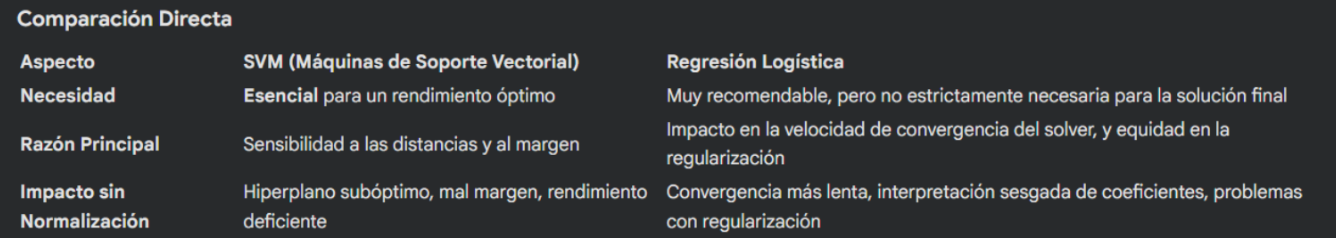

##¿Qué mejoras propondrías para aumentar el rendimiento de los modelos?


Experimentar con diferentes solvers y opciones de regularización (penalty='l1', penalty='l2', C como hiperparámetro), incluso con GridSearch o RandomizedSearchCV.

Aplicación de otros modelos como Random Forest
